In [162]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/fedesoriano/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv


## Import dataset

In [163]:
import pandas as pd
dataset_filepath="/kaggle/input/datasets/fedesoriano/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv"

df_in = pd.read_csv(dataset_filepath)
df_in.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


## Explore attributes and drop Null

In [164]:
print("Non NA count")
print(df_in.count())
print("-----------------------")
print("NA on each Attributes:")
print(df_in.isnull().sum().sort_values(ascending=True))

Non NA count
id                   5110
gender               5110
age                  5110
hypertension         5110
heart_disease        5110
ever_married         5110
work_type            5110
Residence_type       5110
avg_glucose_level    5110
bmi                  4909
smoking_status       5110
stroke               5110
dtype: int64
-----------------------
NA on each Attributes:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
smoking_status         0
stroke                 0
bmi                  201
dtype: int64


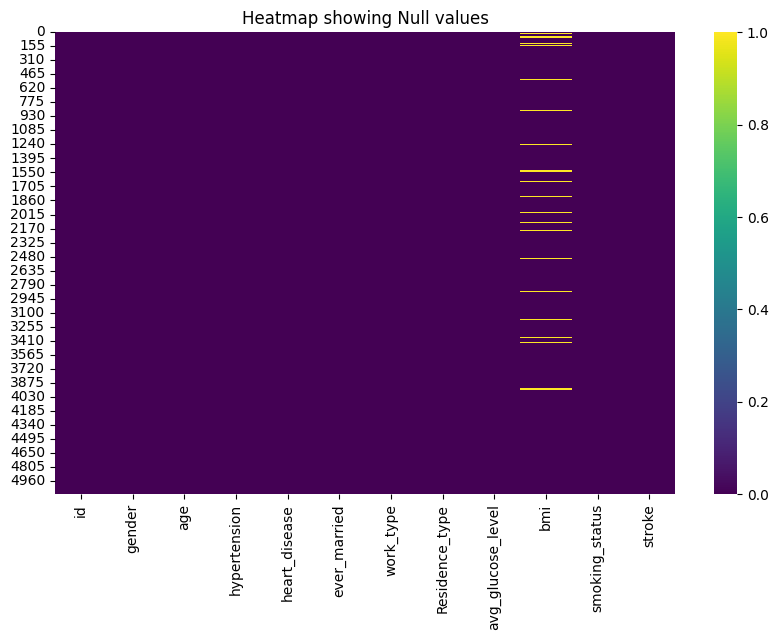

In [165]:
import seaborn as sns

plt.figure(figsize=(10,6))
sns.heatmap(df_in.isnull(), cmap='viridis')
plt.title("Heatmap showing Null values")
plt.show()

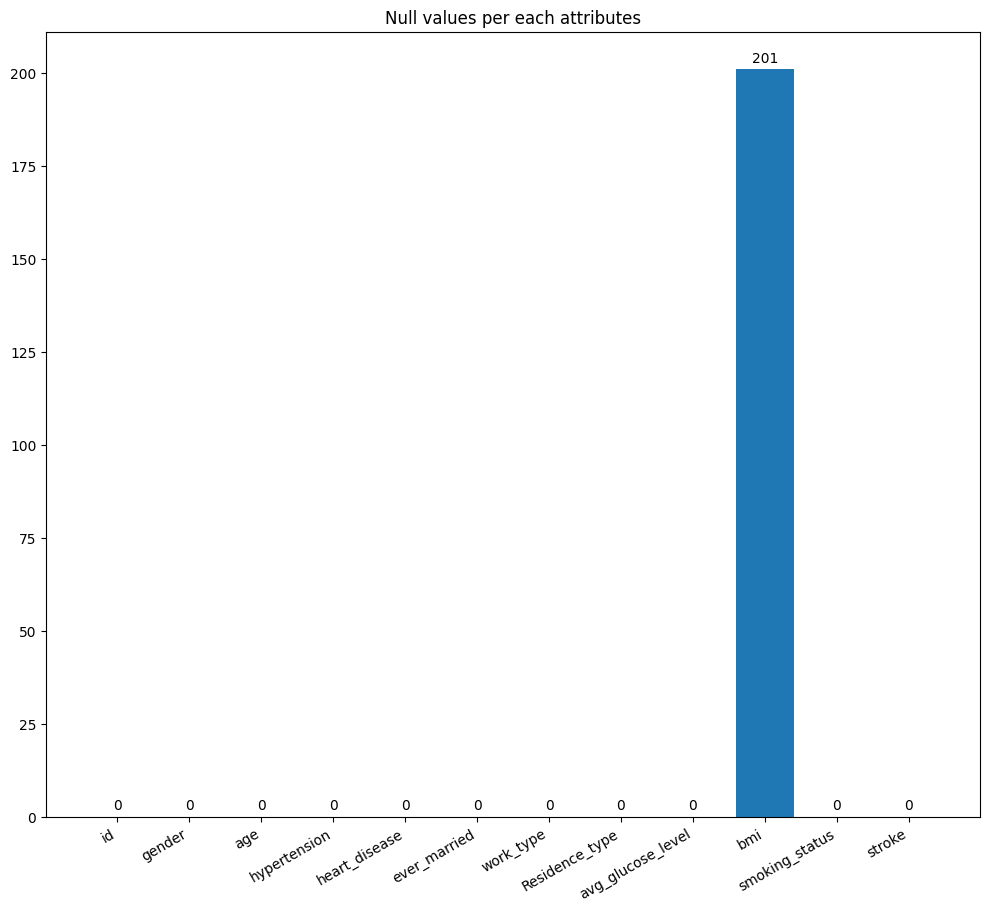

In [166]:
plt.figure(figsize=(10,9))
bars = plt.bar(df_in.columns, df_in.isnull().sum())
plt.bar_label(bars, padding=3,rotation=0, fmt='%d')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.title('Null values per each attributes')
plt.show()

In [167]:
# drop NA
df = df_in.dropna()
# convert datatypes to suitable
df = df.convert_dtypes()
print("NA dropped")

NA dropped


In [168]:
df.count()

id                   4909
gender               4909
age                  4909
hypertension         4909
heart_disease        4909
ever_married         4909
work_type            4909
Residence_type       4909
avg_glucose_level    4909
bmi                  4909
smoking_status       4909
stroke               4909
dtype: int64

In [169]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [170]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,4909.0,4909.0,4909.0,4909.0,4909.0,4909.0,4909.0
mean,37064.313506,42.865374,0.091872,0.049501,105.30515,28.893237,0.042575
std,20995.098457,22.555115,0.288875,0.216934,44.424341,7.854067,0.201917
min,77.0,0.08,0.0,0.0,55.12,10.3,0.0
25%,18605.0,25.0,0.0,0.0,77.07,23.5,0.0
50%,37608.0,44.0,0.0,0.0,91.68,28.1,0.0
75%,55220.0,60.0,0.0,0.0,113.57,33.1,0.0
max,72940.0,82.0,1.0,1.0,271.74,97.6,1.0


## Plot dataset distribution

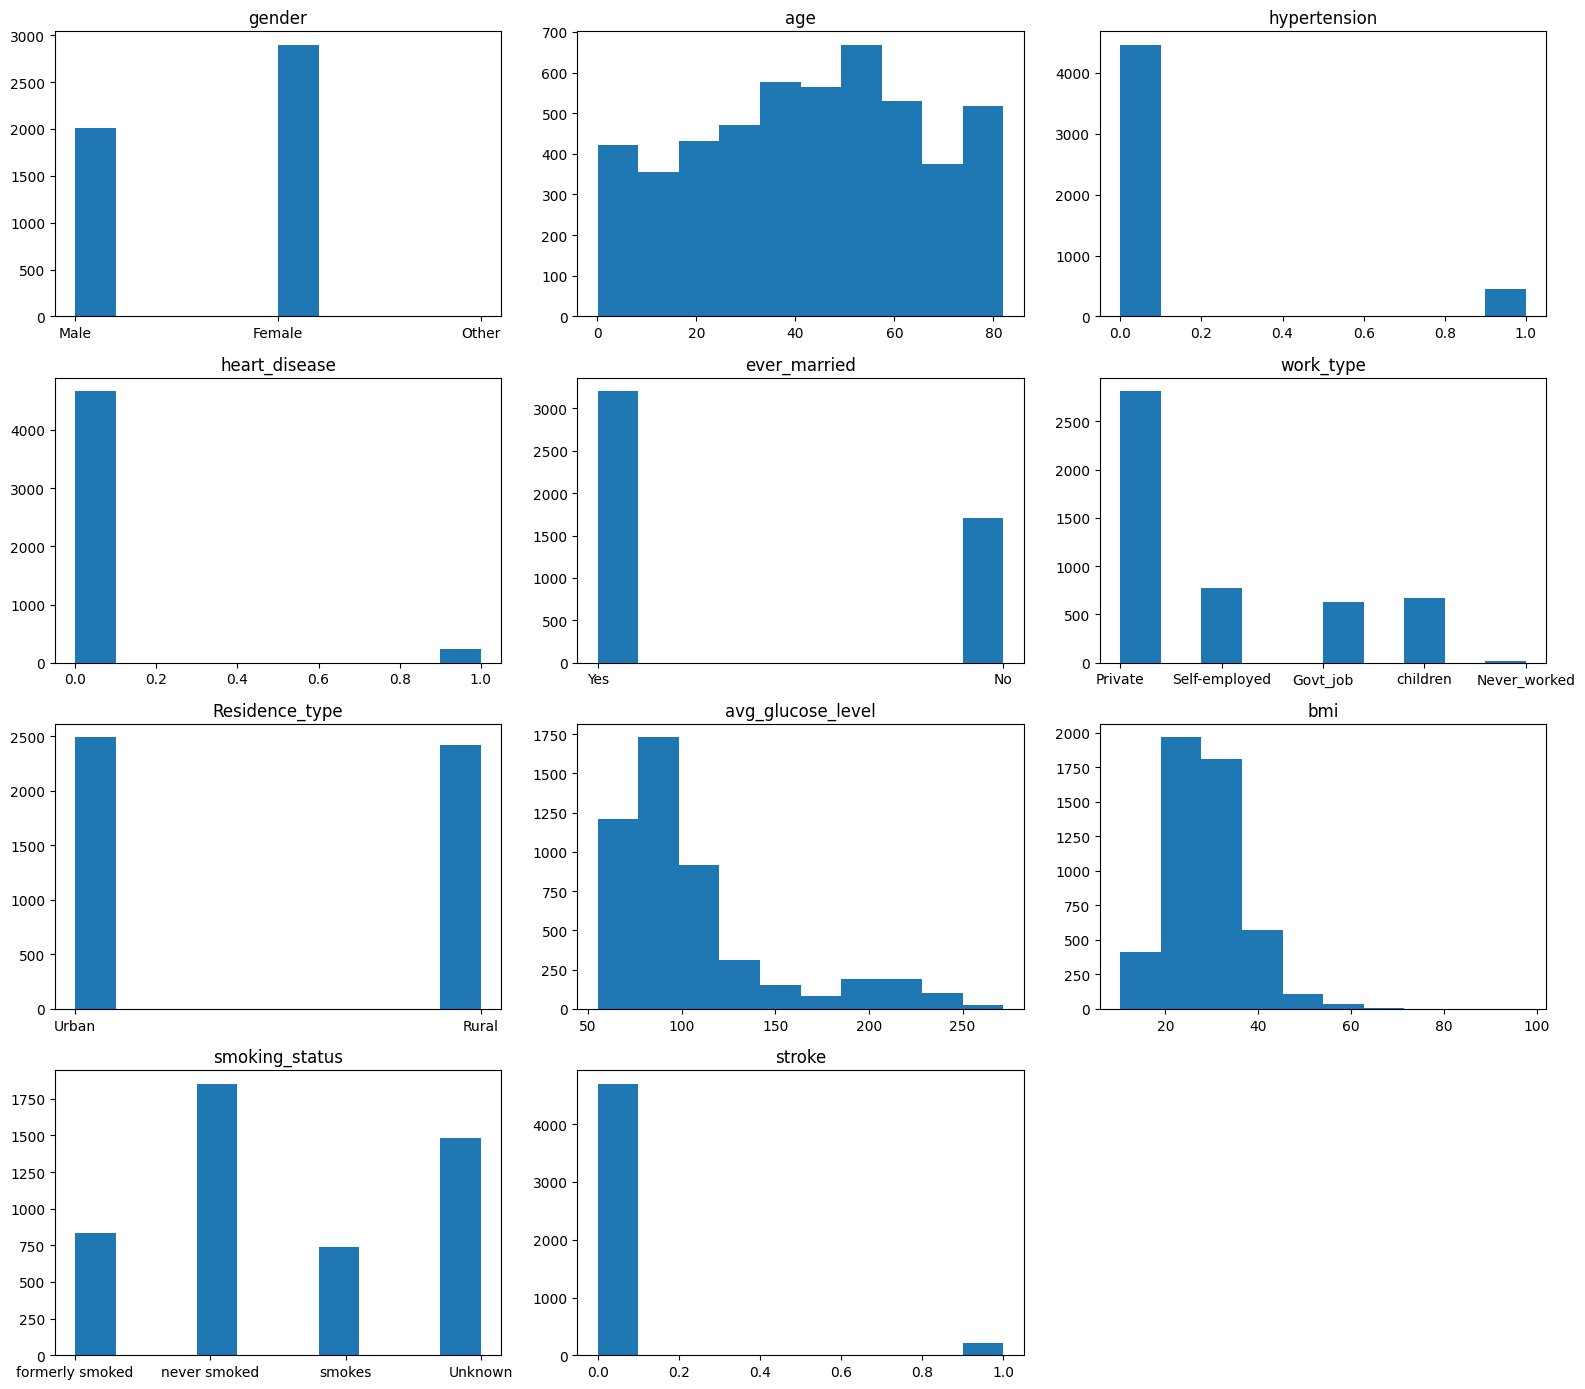

In [171]:
import matplotlib.pyplot as plt
import math
def plot_distribution(idf):
    cols = idf.columns
    col_len = len(cols)
    num_cols = 3
    num_rows = math.ceil(col_len/num_cols)
    it=0
    plt.figure(figsize=(16, num_rows * 3.5))
    for col in cols:
        it=it+1
        plt.subplot(num_rows,num_cols,it)
        if df[col].dtype in [int,float]:
            plt.hist(idf[col],50)
        else:
            plt.hist(idf[col])
        plt.title(col)
    plt.subplots_adjust(hspace=0.5, wspace=0.3)
    plt.tight_layout()
    plt.show()

plot_distribution(df.drop(columns=['id']))

## Encode data and Normalize using Min-Max Normalization

In [176]:
# create a copy and convert all headers to lowercase
df_encoded = df.copy()
df_encoded.columns = [x.lower() for x in df.columns]

# Normalize dataset and convert categories into numbers

# convert categories to numerical manually
smoking_status = {'formerly smoked': 1, 'never smoked': 0, 'smokes': 2, 'unknown':-1}
residence_type= {'urban':1, 'rural':0}
ever_married={'yes':1, 'no':0}
gender = {'male':1, 'female':2, 'others':3}
work_type = {'private':3, 'self-employed':4,'govt_job':2,'children':1,'never_worked':0}

categorical_columns = ['smoking_status','residence_type','ever_married','gender','work_type']

#Convert to lower case
for category in categorical_columns:
    df_encoded[category] = df_encoded[category].apply(lambda x: x.lower())

# convert to category
# for category in categorical_columns:
#     df_encoded[category] = df_encoded[category].astype('category')

# use manual mapping
df_encoded['smoking_status'] = df_encoded['smoking_status'].map(smoking_status)
df_encoded['residence_type'] = df_encoded['residence_type'].map(residence_type)
df_encoded['ever_married'] = df_encoded['ever_married'].map(ever_married)
df_encoded['gender'] = df_encoded['gender'].map(gender)
df_encoded['work_type'] = df_encoded['work_type'].map(work_type)

for column in df_encoded.columns:
    if column not in categorical_columns:
        df_encoded[column] = (df_encoded[column] - df[column].min())/(df_encoded[column].max() - df[column].min())

# use one-hot-encoder

#df_encoded = pd.get_dummies(df_encoded, columns=['work_type'], dtype=int)
#df_encoded = pd.get_dummies(df_encoded, columns=['gender'], dtype=int)
#df_encoded = pd.get_dummies(df_encoded, columns=['residence_type'], dtype=int)

## Visualize relation among attributes

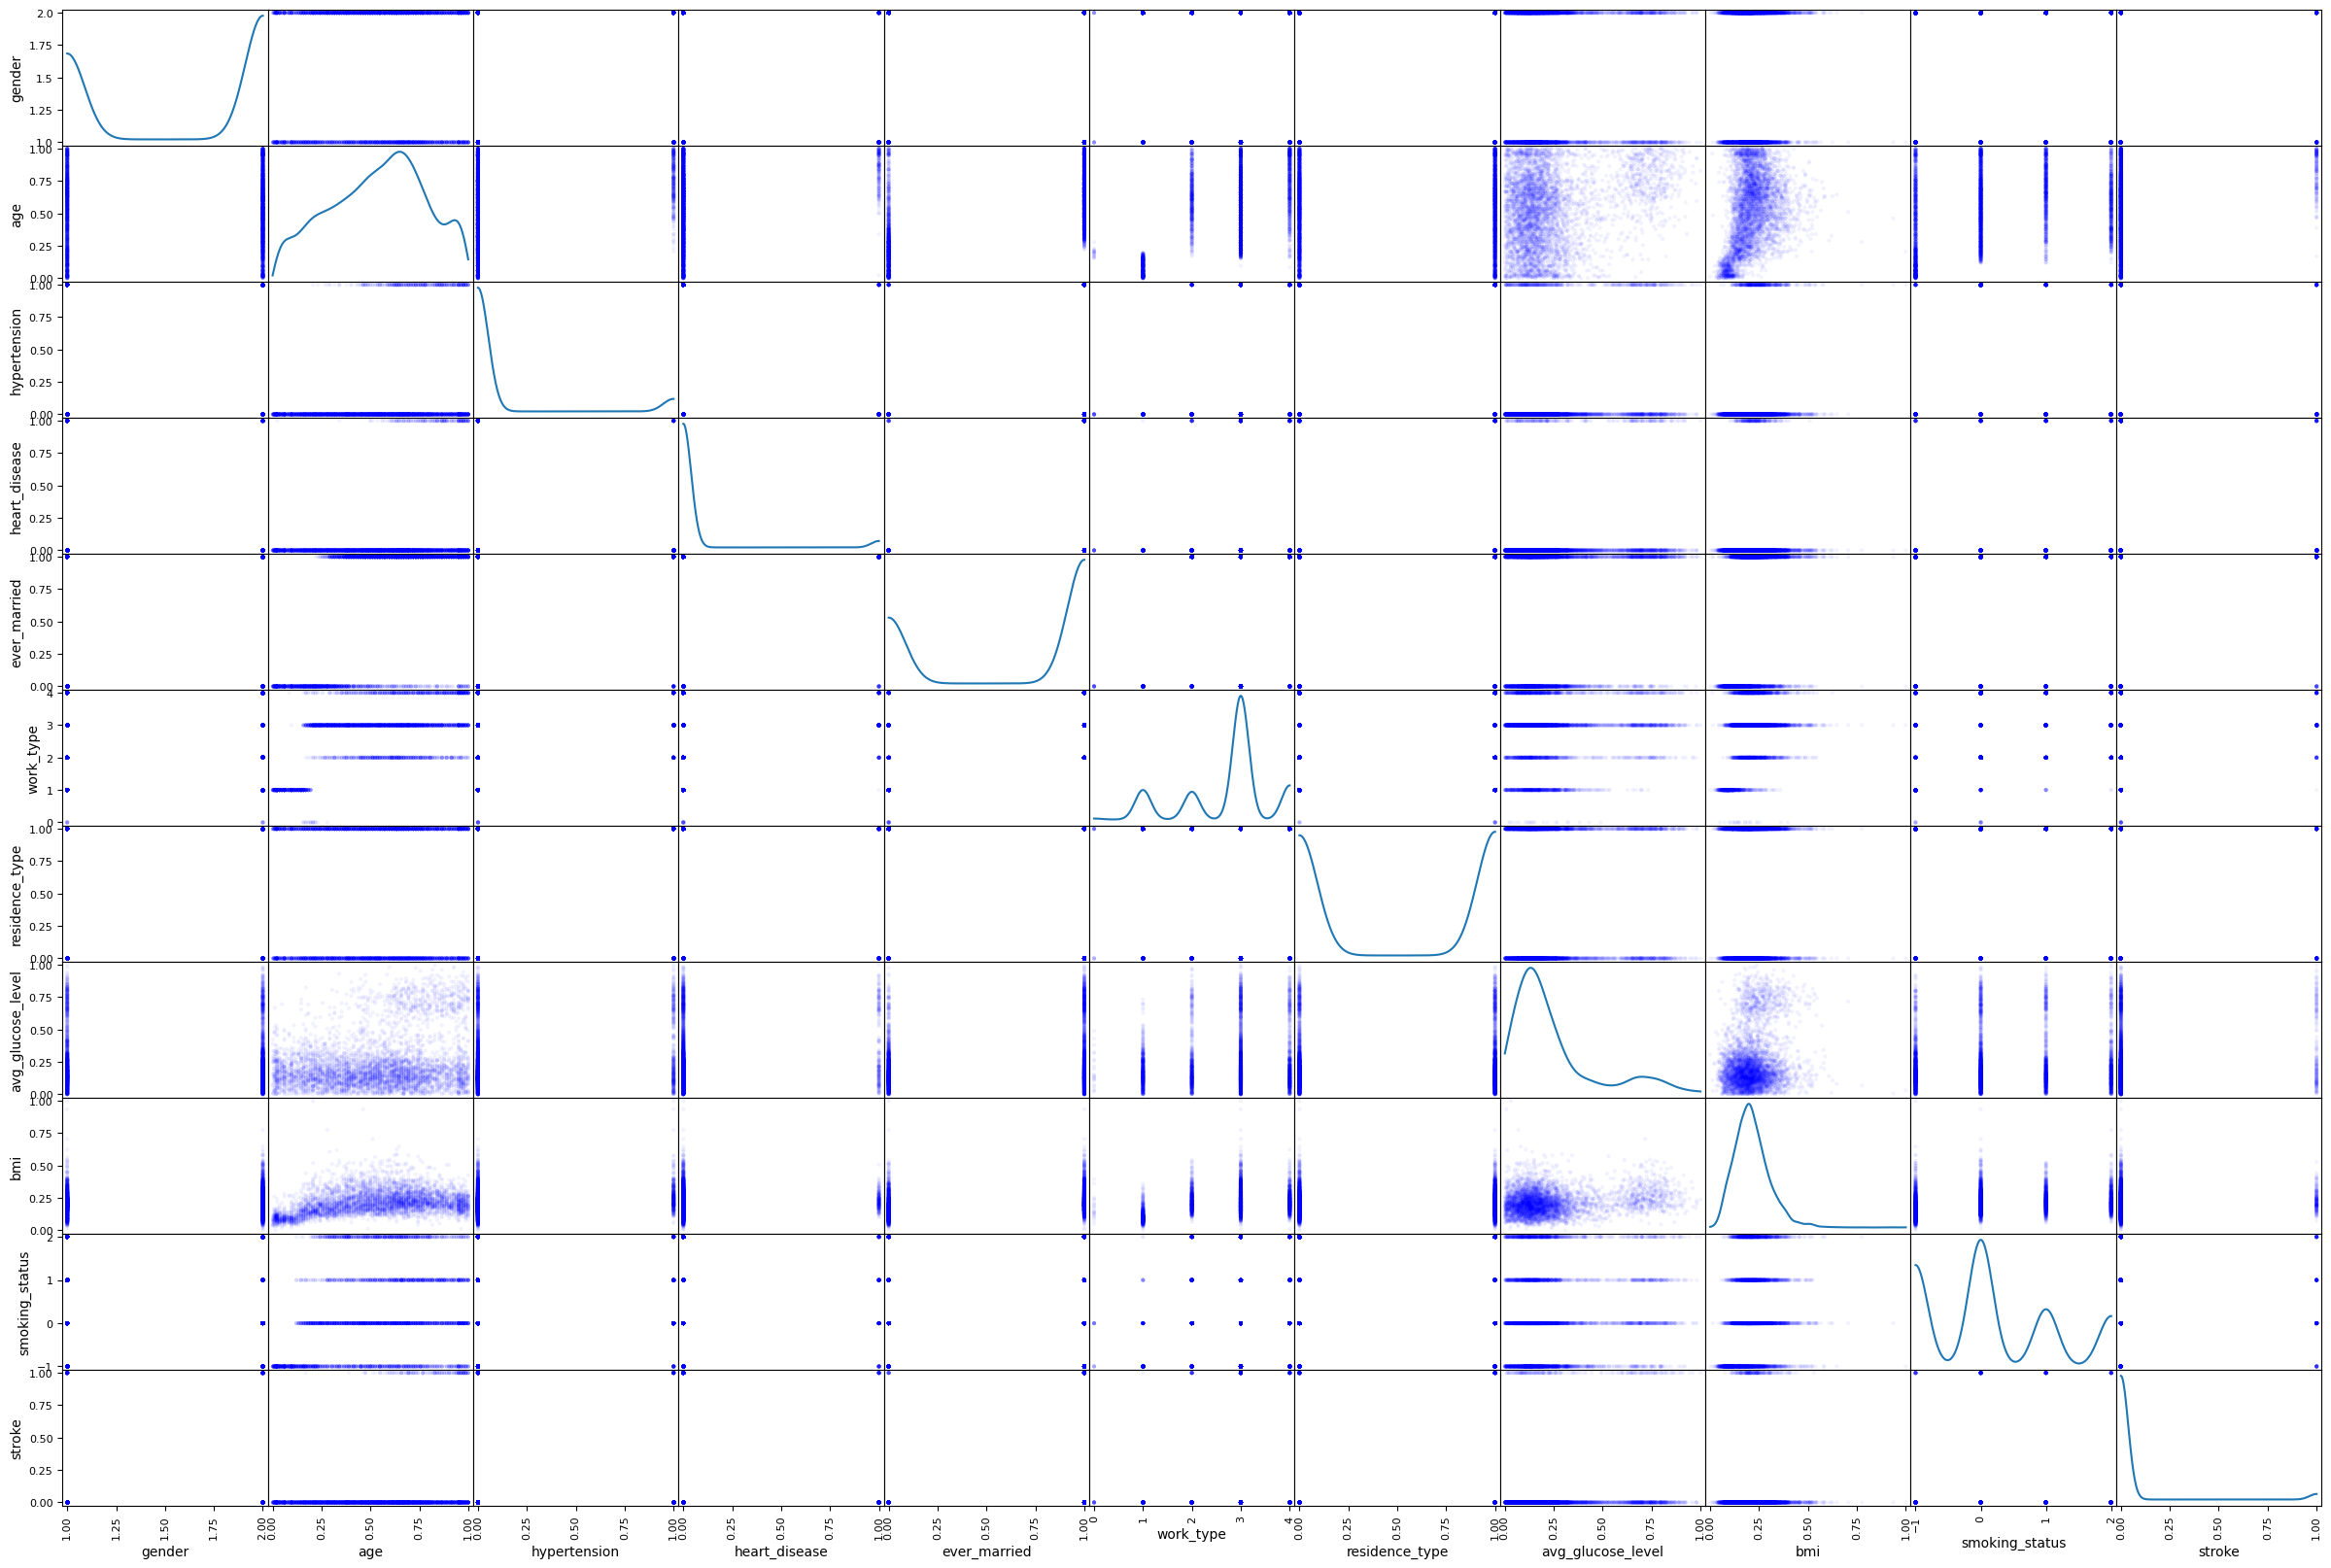

In [201]:
from pandas.plotting import scatter_matrix

def remove_cat_row(df, col_name,value):
    return df[df[col_name]!=value]

scatter_matrix(df_encoded.drop(columns=['id']),
               color='blue',
               grid=True,
               alpha=0.05,
               diagonal='kde',
               figsize=(30,20))
plt.show()

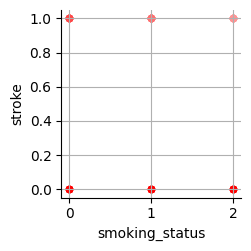

In [199]:
g = sns.pairplot(df_encoded[df_encoded['smoking_status']!=-1],
               x_vars = ['smoking_status'],
               y_vars = ['stroke'],
               plot_kws={'color': 'red', 'alpha': 0.01})

for ax in g.axes.flat:
    ax.grid(True)
plt.show()

In [174]:
0.25*(97.6-10.3)

21.825

From Above Plot,
* Many Older aged are suffering from stroke than young
* People with BMI around 21.8 are likely to have stroke
* People with Low Average glucose level also seem to had a stroke

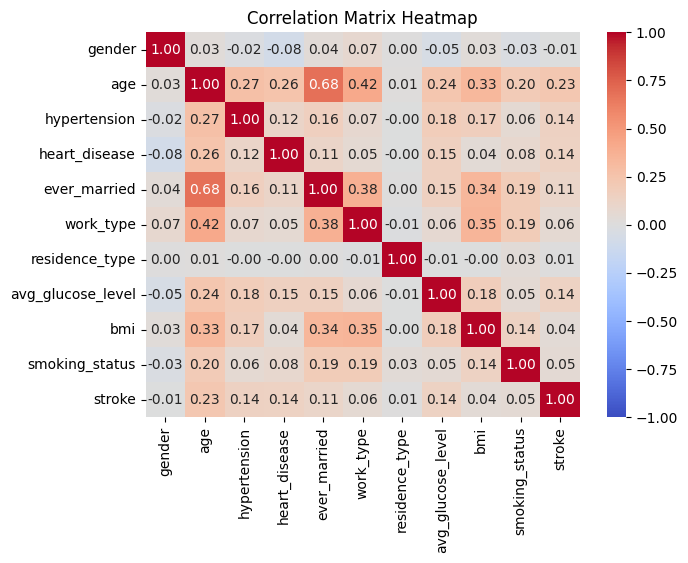

In [161]:
# Show Correlation Matrix

corr_matrix = df_encoded.drop(columns=['id']).corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title('Correlation Matrix Heatmap')
plt.show()

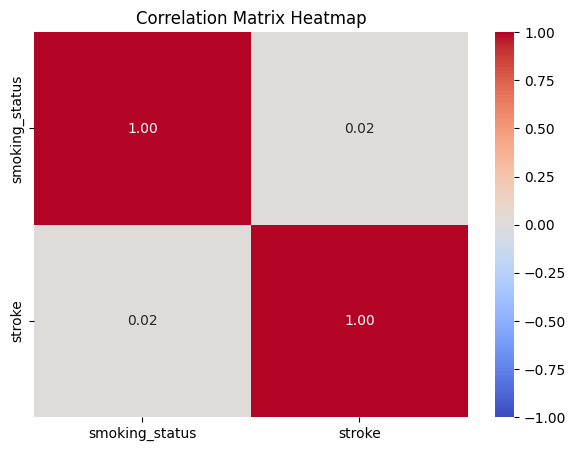

In [205]:
# Show Correlation Matrix with removed unknown smokers
smoking_df = df_encoded[df_encoded['smoking_status']!=-1].drop(columns=[col for col in df_encoded.columns if col not in ['smoking_status','stroke']])

smoking_df['smoking_status'] = (smoking_df['smoking_status'] - smoking_df['smoking_status'].min())/(smoking_df['smoking_status'].max()-smoking_df['smoking_status'].min())
corr_matrix = smoking_df.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
)

plt.title('Correlation Matrix Heatmap')
plt.show()

**Age** ,**heart disease**, **hyper_tension**, and **avg_glucose_level** are the most strong cause of stroke

**Smoking** seems to not relate with stroke